# Portfolio Optimization : Ledoit-Wolf Shrinkage

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from portfolio_optimization.data_loader import fetch_returns
from spectral_analysis.denoising import (
    compute_bulk_bounds,
    estimate_noise_variance,
    marchenko_pastur_pdf,
)

In [2]:
START = pd.Timestamp("2023-01-01")
END = pd.Timestamp("2024-01-01")

In [10]:
df_returns = fetch_returns(start=START, end=END)

[*********************100%***********************]  100 of 100 completed


In [4]:
concentration_ratio = df_returns.shape[1]/df_returns.shape[0]

In [5]:
eigenvalues = np.linalg.eigvalsh(df_returns.corr().to_numpy())

In [6]:
noise_variance = estimate_noise_variance(
    eigenvalues=eigenvalues,
    concentration_ratio=concentration_ratio,
)

In [7]:
X = np.linspace(0, 1.01*eigenvalues.max(), 101)

In [8]:
mp_pdf = marchenko_pastur_pdf(
    x=X,
    concentration_ratio=concentration_ratio,
    noise_variance=noise_variance,
    bulk_bounds=compute_bulk_bounds(
        concentration_ratio=concentration_ratio,
        noise_variance=noise_variance
    )
)

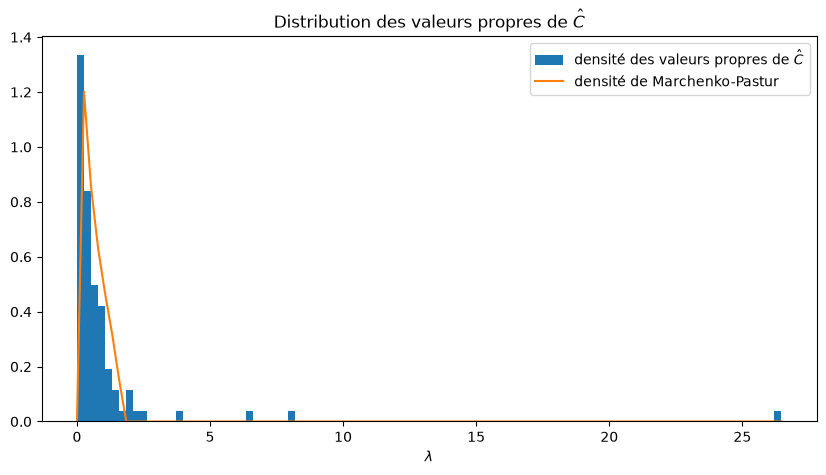

In [9]:
fig, ax = plt.subplots()
fig.set_size_inches(10, 5)

ax.set_title(r"Distribution des valeurs propres de $\hat{C}$")

ax.hist(eigenvalues, density=True, bins=X, label=r"densité des valeurs propres de $\hat{C}$")
ax.plot(X, mp_pdf, label="densité de Marchenko-Pastur")

ax.legend()
ax.set_xlabel(r"$\lambda$")

plt.show()